# Figure S2

In [1]:
from riskhistory.format import rcParams
from riskhistory.config import results_pth
from riskhistory.data import load_ddm_posterior, load_ddm_subj_params, DATASET_LABELS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy import stats

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
FULL_DDM_MODEL = "HDDM_Base_Lag1-full"

### Helper functions

In [2]:
# (column, axis label) -- one row/column of the pairplot each
PAIRPLOT_PARAMS = [
    ("sp_bias",        "Starting-point bias (∆z)"),
    ("drift_bias",     "Drift bias (∆v)"),
    ("valuation_bias", "Valuation bias (∆λ)"),
]
HIST_COLOR = "#91AC67"
SCATTER_COLOR = "#4D4D4D"


def loss_aversion_diff(gain, gain_cp, loss, loss_cp):
    """λ after accept − λ after reject, with λ = |v_loss / v_gain|
    (choice_prev1 coded +1 accept / −1 reject; same as figure3.ipynb's Val-CH)."""
    lambda_accept = np.abs((loss + loss_cp) / (gain + gain_cp))
    lambda_reject = np.abs((loss - loss_cp) / (gain - gain_cp))
    return lambda_accept - lambda_reject


def load_choicehistory_draws(model_id, dataset):
    """Pooled group-level posterior draws (4 chains flattened) of the three
    choice-history biases; the valuation bias is computed draw by draw."""
    posterior = load_ddm_posterior(model_id, dataset)
    draws = {name: posterior[name].flatten() for name in [
        "z_choice_prev1", "v_choice_prev1",
        "v_gain_centered", "v_gain_centered:choice_prev1",
        "v_loss_centered", "v_loss_centered:choice_prev1",
    ]}
    return pd.DataFrame({
        "sp_bias":        2 * draws["z_choice_prev1"],
        "drift_bias":     2 * draws["v_choice_prev1"],
        "valuation_bias": loss_aversion_diff(
            draws["v_gain_centered"], draws["v_gain_centered:choice_prev1"],
            draws["v_loss_centered"], draws["v_loss_centered:choice_prev1"],
        ),
    })


def plot_pairplot(subfig, draws, title, bins=40):
    """Corner pairplot: posterior histogram (mean line, 95% interval bar) on the
    diagonal, draw-by-draw scatter with Pearson r below it, upper triangle empty."""
    n = len(PAIRPLOT_PARAMS)
    axes = subfig.subplots(nrows=n, ncols=n)
    for row, (y_col, y_label) in enumerate(PAIRPLOT_PARAMS):
        for col, (x_col, x_label) in enumerate(PAIRPLOT_PARAMS):
            ax = axes[row, col]
            if col > row:
                ax.set_visible(False)
                continue
            x = draws[x_col]
            if row == col:
                lo, hi = np.percentile(x, [2.5, 97.5])
                ax.hist(x, bins=bins, color=HIST_COLOR, edgecolor="black", linewidth=0.8)
                ax.axvline(x.mean(), color="black", linewidth=2.5)
                ax.plot([lo, hi], [0, 0], color="black", linewidth=5, solid_capstyle="butt",
                        clip_on=False, zorder=4)
                ax.set_yticks([])
                ax.spines["left"].set_visible(False)
            else:
                y = draws[y_col]
                ax.scatter(x, y, s=1, alpha=0.05, color=SCATTER_COLOR, rasterized=True)
                r = np.corrcoef(x, y)[0, 1]
                ax.text(0.05, 0.95, f"r = {r:.2f}", transform=ax.transAxes,
                        ha="left", va="top", fontsize=plt.rcParams["axes.labelsize"],
                        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8})
                ax.axhline(0, color="#aaaaaa", linewidth=1.5, linestyle="--", zorder=0)
                ax.axvline(0, color="#aaaaaa", linewidth=1.5, linestyle="--", zorder=0)
                if col == 0:
                    ax.set_ylabel(y_label)
                else:
                    ax.tick_params(labelleft=False)
            if row == n - 1:
                ax.set_xlabel(x_label)
            else:
                ax.tick_params(labelbottom=False)
            ax.spines[["top", "right"]].set_visible(False)

    # share x within each column and y within each row (off the diagonal)
    for col in range(n):
        for row in range(col + 1, n):
            axes[row, col].sharex(axes[col, col])
    for row in range(n):
        for col in range(1, row):
            axes[row, col].sharey(axes[row, 0])
    subfig.suptitle(title, fontsize=plt.rcParams["axes.titlesize"]*2)

### Pairplot: choice-history biases in the full DDM
Pooled group-level posterior draws (4 chains) of `HDDM_Base_Lag1-full`, one corner pairplot per dataset. Diagonal: posterior histogram (black line = mean, bar = 95% posterior interval). Below the diagonal: draw-by-draw scatter with the Pearson correlation across draws, i.e. the posterior trade-off between the two biases. Starting-point and drift biases are 2 x the ±1-coded `choice_prev1` effect (accept − reject); the valuation bias is λ after accept − λ after reject, with λ = |v_loss / v_gain|.

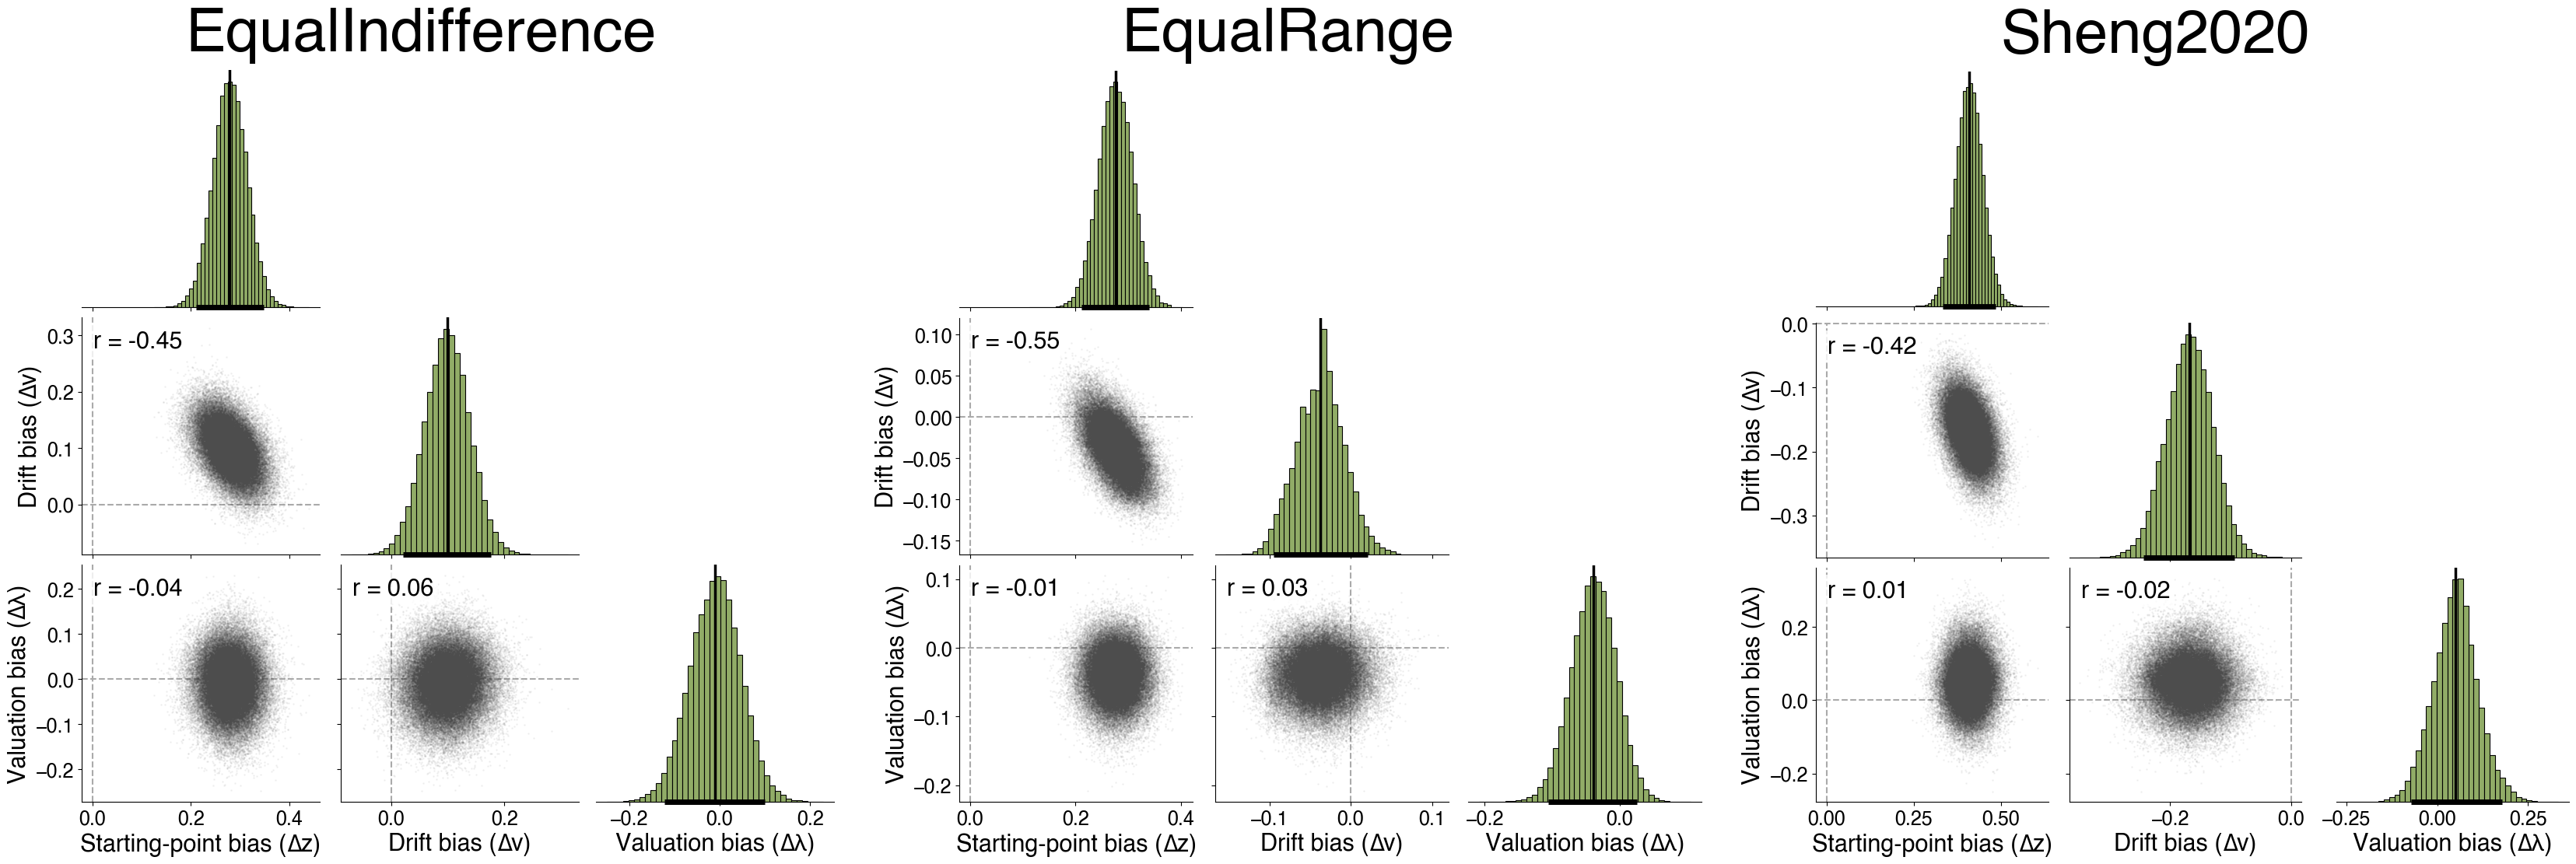

In [3]:
choicehistory_draws = {ds: load_choicehistory_draws(FULL_DDM_MODEL, ds) for ds in DATASETS}

fig = plt.figure(figsize=(33, 11), layout="constrained")
subfigs = fig.subfigures(nrows=1, ncols=len(DATASETS), wspace=0.04)
for subfig, ds in zip(subfigs, DATASETS):
    plot_pairplot(subfig, choicehistory_draws[ds], DATASET_LABELS[ds])

fig.savefig("saved/figure_S2.svg", dpi=300, bbox_inches="tight")
plt.show()

### Table: full DDM choice-history biases
Group-level posterior mean [95% posterior interval] per dataset, written to `results/ddm_full_choicehistory_posterior_tables.tex` in the format of `figure6.ipynb`'s table.

In [4]:
TABLE_DATASET_NAMES = {
    "equalIndifference": "EqualIndifference",
    "equalRange": "EqualRange",
    "sheng2020": "Sheng2020",
}
TABLE_PARAM_LABELS = {
    "sp_bias":        "Starting-point bias ($2 \\times z_{\\mathrm{choice\\_prev1}}$)",
    "drift_bias":     "Drift bias ($2 \\times v_{\\mathrm{choice\\_prev1}}$)",
    "valuation_bias": "Valuation bias ($\\lambda_{A} - \\lambda_{R}$)",
}

rows = []
for param, _ in PAIRPLOT_PARAMS:
    for ds in DATASETS:
        samples = choicehistory_draws[ds][param]
        lo, hi = np.percentile(samples, [2.5, 97.5])
        rows.append({"parameter": param, "dataset": ds,
                     "mean": samples.mean(), "ci_lower": lo, "ci_upper": hi})
posterior_summary = pd.DataFrame(rows)
print(posterior_summary.round(3).to_string(index=False))


def format_posterior_cell(row):
    """Mean [95% posterior interval]."""
    return f"{row['mean']:.3f} [{row['ci_lower']:.3f}, {row['ci_upper']:.3f}]"


def write_posterior_table(f, title, caption, summary):
    f.write(f"\\subsection*{{{title}}}\n\n")
    f.write("\\begin{table}[h!]\n")
    f.write("\\centering\n")
    f.write("\\begin{tabular}{l" + "c" * len(DATASETS) + "}\n")
    f.write("\\hline\n")
    header = ["Parameter"] + [TABLE_DATASET_NAMES[ds] for ds in DATASETS]
    f.write(" & ".join(header) + " \\\\\n")
    f.write("\\hline\n")
    for param, _ in PAIRPLOT_PARAMS:
        cells = [TABLE_PARAM_LABELS[param]]
        for ds in DATASETS:
            row = summary[(summary["parameter"] == param) & (summary["dataset"] == ds)].iloc[0]
            cells.append(format_posterior_cell(row))
        f.write(" & ".join(cells) + " \\\\\n")
    f.write("\\hline\n")
    f.write("\\end{tabular}\n")
    f.write(f"\\caption{{{caption}}}\n")
    f.write("\\end{table}\n\n\n")
    f.write("\\newpage\n")


title = "Choice-history biases in the full DDM"
caption = (
    "Group-level posterior mean [95\\% posterior interval] "
    "(2.5th--97.5th percentiles of the pooled samples) of the choice-history biases "
    "in the full DDM. Starting-point and drift biases are the accept $-$ reject "
    "difference ($2\\times$ the $\\pm1$-coded effect); the valuation bias is the loss "
    "aversion $\\lambda = |v_{\\mathrm{loss}} / v_{\\mathrm{gain}}|$ after accept $-$ after reject."
)

output_path = results_pth / "ddm_full_choicehistory_posterior_tables.tex"
with open(output_path, "w") as f:
    write_posterior_table(f, title, caption, posterior_summary)

print()
print(output_path.read_text())

     parameter           dataset   mean  ci_lower  ci_upper
       sp_bias equalIndifference  0.279     0.210     0.348
       sp_bias        equalRange  0.276     0.211     0.340
       sp_bias         sheng2020  0.409     0.334     0.485
    drift_bias equalIndifference  0.099     0.021     0.176
    drift_bias        equalRange -0.037    -0.095     0.021
    drift_bias         sheng2020 -0.168    -0.244    -0.093
valuation_bias equalIndifference -0.010    -0.122     0.099
valuation_bias        equalRange -0.039    -0.106     0.025
valuation_bias         sheng2020  0.050    -0.072     0.177

\subsection*{Choice-history biases in the full DDM}

\begin{table}[h!]
\centering
\begin{tabular}{lccc}
\hline
Parameter & EqualIndifference & EqualRange & Sheng2020 \\
\hline
Starting-point bias ($2 \times z_{\mathrm{choice\_prev1}}$) & 0.279 [0.210, 0.348] & 0.276 [0.211, 0.340] & 0.409 [0.334, 0.485] \\
Drift bias ($2 \times v_{\mathrm{choice\_prev1}}$) & 0.099 [0.021, 0.176] & -0.037 [-0.095,

### Between-participant correlations of the choice-history biases
Per-participant posterior means from `results/analysis_ddm/hddm_params/HDDM_Base_Lag1-full_{dataset}_subj_params.csv`: starting-point bias = 2 x `z_choice_prev1`, drift bias = 2 x `v_choice_prev1`, valuation bias = λ after accept − λ after reject computed from each participant's gain/loss drift weights. Pearson r and Spearman ρ (rank-based, robust to the occasional extreme λ from a participant with a near-zero gain weight), each with its p-value.

In [5]:
def load_choicehistory_subj(model_id, dataset):
    """Per-participant posterior means of the three choice-history biases."""
    params = (load_ddm_subj_params(model_id, dataset)
              .pivot(index="sub", columns="param_name", values="param_value"))
    return pd.DataFrame({
        "sp_bias":        2 * params["z_choice_prev1"],
        "drift_bias":     2 * params["v_choice_prev1"],
        "valuation_bias": loss_aversion_diff(
            params["v_gain_centered"], params["v_gain_centered:choice_prev1"],
            params["v_loss_centered"], params["v_loss_centered:choice_prev1"],
        ),
    })


PARAM_SHORT = {"sp_bias": "Starting point", "drift_bias": "Drift", "valuation_bias": "Valuation"}

subj_corr_rows = []
for ds in DATASETS:
    subj = load_choicehistory_subj(FULL_DDM_MODEL, ds)
    for (x_col, _), (y_col, _) in combinations(PAIRPLOT_PARAMS, 2):
        pearson = stats.pearsonr(subj[x_col], subj[y_col])
        spearman = stats.spearmanr(subj[x_col], subj[y_col])
        subj_corr_rows.append({
            "dataset": DATASET_LABELS[ds], "n": len(subj),
            "pair": f"{PARAM_SHORT[x_col]} vs. {PARAM_SHORT[y_col]}",
            "pearson_r": pearson.statistic, "pearson_p": pearson.pvalue,
            "spearman_rho": spearman.statistic, "spearman_p": spearman.pvalue,
        })

subj_correlations = pd.DataFrame(subj_corr_rows)
print(subj_correlations.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

          dataset  n                         pair  pearson_r  pearson_p  spearman_rho  spearman_p
EqualIndifference 54     Starting point vs. Drift      0.343      0.011         0.337       0.013
EqualIndifference 54 Starting point vs. Valuation      0.062      0.654         0.098       0.483
EqualIndifference 54          Drift vs. Valuation     -0.133      0.336         0.075       0.588
       EqualRange 54     Starting point vs. Drift      0.266      0.052         0.331       0.015
       EqualRange 54 Starting point vs. Valuation      0.239      0.082         0.163       0.240
       EqualRange 54          Drift vs. Valuation      0.089      0.521         0.066       0.636
        Sheng2020 82     Starting point vs. Drift      0.464      0.000         0.448       0.000
        Sheng2020 82 Starting point vs. Valuation      0.016      0.885        -0.022       0.846
        Sheng2020 82          Drift vs. Valuation     -0.095      0.395        -0.006       0.957
